# Drone RL — independent PPO, DQN, and SAC results

To view a saved result, run **Setup**, **Load the RNN**, **Choose a mission**,
and **Plot helpers**, then
run only the desired enabled algorithm's **Results** cell. No training cell or other
algorithm's results cell is required. Checkpoint paths are editable in Setup.
Set `SKIP_DQN` / `SKIP_SAC` in Setup; both default to `True` and skip training
and results, so Run All runs PPO only. Choose the mission before creating environments.

Each algorithm has an optional training cell, its own flight plot,
and its own learning curve. Physical state stays `[z, vz, az]`; the policy observes
`[z-z_ref, vz, az]`. Training, evaluation, plots, and exports use the selected mission.


## Setup


In [1]:
# Run once if needed, then restart the kernel:
# %pip install gymnasium stable-baselines3 numpy matplotlib scipy

import ast
import io
import zipfile
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import gymnasium as gym
from stable_baselines3 import PPO, DQN, SAC
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.results_plotter import load_results

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "rnn_model/rnn_training.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from the drone project or rl_interface/ to find rnn_model/rnn_training.py")
sys.path.insert(0, str(PROJECT_ROOT / "rl_interface"))
from lib.droneEnv import DroneEnv, PARAMS, Z_LAND, default_mission, run_episode, evaluate

from stable_baselines3.common.callbacks import EvalCallback, StopTrainingOnRewardThreshold

SEED = 0
# Skip both training and results for these algorithms during Run All.
SKIP_DQN = True
SKIP_SAC = True
torch.set_num_threads(1)
# Saved results: edit one path to inspect a different checkpoint.
PPO_MODEL_PATH = PROJECT_ROOT / 'rl_interface/logs/rl_comparison_20261103_155235/ppo/ppo_drone_rnn.zip'
DQN_MODEL_PATH = PROJECT_ROOT / 'rl_interface/logs/tuning_dqn_multistep_20261103_163054/best_model.zip'
SAC_MODEL_PATH = PROJECT_ROOT / 'rl_interface/logs/tuning_sac_smooth_20261103_163155/best_model.zip'

# New training runs get separate folders; plotting does not create or require them.
RUN_DIR = PROJECT_ROOT / "rl_interface" / "logs" / f"rl_tuned_{time.strftime('%Y%m%d_%H%M%S')}"
LOG_DIR = PROJECT_ROOT / "rl_interface" / "export_logs" 
PPO_DIR = RUN_DIR / "ppo"
PPO_STEPS = 500000
PPO_PARAMS = {'learning_rate': 0.0001,
 'n_steps': 256,
 'batch_size': 128,
 'gamma': 0.99,
 'gae_lambda': 0.95,
 'n_epochs': 10,
 'clip_range': 0.2}
DQN_DIR = RUN_DIR / "dqn"
DQN_STEPS = 500000
DQN_PARAMS = {'learning_rate': 0.0001,
 'buffer_size': 100000,
 'learning_starts': 1000,
 'batch_size': 128,
 'train_freq': 5,
 'gradient_steps': -1,
 'n_steps': 3,
 'target_update_interval': 1000,
 'tau': 0.1,
 'exploration_fraction': 1.0,
 'policy_kwargs': {'net_arch': [64, 64]}}
SAC_DIR = RUN_DIR / "sac"
SAC_STEPS = 500000
SAC_PARAMS = {'learning_rate': 0.0003,
 'buffer_size': 100000,
 'learning_starts': 1000,
 'batch_size': 128,
 'train_freq': 1,
 'gradient_steps': -1,
 'ent_coef': 'auto_0.05',
 'use_sde': True,
 'sde_sample_freq': 4,
 'use_sde_at_warmup': True,
 'policy_kwargs': {'net_arch': [64, 64], 'log_std_init': -2}}
SAC_ACTION_LIMIT = 0.8


## Load the trained RNN and head

Use `ModelNN` from `rnn_model/rnn_training.py`, with its 32-hidden-unit RNN
and linear head. Load only the class definition: importing the entire script
would also read its CSVs and start 700 training epochs.

`rnn_model/rnn_model_robust` contains an extracted PyTorch state dict.
Repack its existing files in memory so `torch.load(weights_only=True)` can
read the checkpoint. Strict loading checks all RNN and head weights.

The existing library runs `out, h = model.rnn(x, h)` followed by `model.head(out)`.
Each episode starts with `h=None`; subsequent steps reuse the returned hidden
tensor. Each parallel environment keeps its own hidden tensor. No command
history or full-sequence replay is needed.


In [2]:
training_path = PROJECT_ROOT / "rnn_model/rnn_training.py"
definition = next(
    node for node in ast.parse(training_path.read_text()).body
    if isinstance(node, ast.ClassDef) and node.name == "ModelNN"
)
exec(compile(ast.Module(body=[definition], type_ignores=[]), str(training_path), "exec"))

model_path = PROJECT_ROOT / "rnn_model/rnn_model_robust"
buffer = io.BytesIO()
with zipfile.ZipFile(buffer, "w", strict_timestamps=False) as archive:
    for file in sorted(model_path.rglob("*")):
        if file.is_file():
            archive.write(file, f"checkpoint/{file.relative_to(model_path).as_posix()}")
buffer.seek(0)
weights = torch.load(buffer, map_location="cpu", weights_only=True)

acceleration_rnn = ModelNN(1, 1, "RNN", 32, 1)
load_result = acceleration_rnn.load_state_dict(weights, strict=True)
acceleration_rnn.eval().requires_grad_(False)

print("Model:", model_path)
print("Load:", load_result)
print("RNN:", acceleration_rnn.rnn)
print("Head:", acceleration_rnn.head)


Model: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rnn_model/rnn_model_robust
Load: <All keys matched successfully>
RNN: RNN(1, 32, batch_first=True)
Head: Linear(in_features=32, out_features=1, bias=True)


## Choose a mission

Edit `ref_mission(t)` below. All environments use it for training, evaluation,
and export. Rerun this cell and recreate environments after editing it.

The environment supplies only `ref_mission(t)` at the current time. The policy
receives `[z - z_ref(t), vz, az]`; the mission function and future targets are
not policy inputs. Full reference curves are used only for plots and reference
generation during MATLAB replay.


In [3]:
def ref_mission(t):
    """Hold at 0 m until 2 s, target 2 m until 6 s, then land."""
    if t < 2.0:
        return 0.0
    elif t < 6.0:
        return 2.0
    else:
        return Z_LAND



## Plot helpers

Shared action wrappers and plotting functions; this cell does not train or load a policy.


In [4]:
DQN_COMMANDS = np.linspace(-3.0, 3.0, 61, dtype=np.float32)

class DiscreteDroneActions(gym.ActionWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.action_space = gym.spaces.Discrete(len(DQN_COMMANDS))

    def action(self, index):
        return np.array([DQN_COMMANDS[int(index)]], dtype=np.float32)

class LimitedCommands(gym.Wrapper):
    def __init__(self, env, limit):
        super().__init__(env)
        self.action_space = gym.spaces.Box(-limit, limit, (1,), dtype=np.float32)

def show_result(name, checkpoint, mission_to_test = None):
    checkpoint = Path(checkpoint)
    load_kwargs = {"replay_buffer_class": None} if name == "DQN" else {}
    model = {"PPO": PPO, "DQN": DQN, "SAC": SAC}[name].load(checkpoint, device="cpu", **load_kwargs)
    commands = np.load(checkpoint.parent / "commands.npy") if name == "DQN" else None

    def learned_policy(obs):
        action = model.predict(obs, deterministic=True)[0]
        return np.array([commands[int(action)]], dtype=np.float32) if commands is not None else action

    if mission_to_test is not None:
        eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=mission_to_test)
    else:
        eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
    print(f"{name}: {checkpoint} ({model.num_timesteps:,} training steps)")
    states, actions, total, outcome = run_episode(eval_env, learned_policy, seed=100)
    mission = eval_env.unwrapped.mission
    t = np.arange(len(states)) * eval_env.p.dt
    u = np.asarray(actions).reshape(-1)
    target = np.array([mission(float(ti)) for ti in t[1:]])
    mae = np.mean(np.abs(states[1:, 0] - target))
    rms_du = np.sqrt(np.mean(np.diff(np.r_[0.0, u]) ** 2))
    print(f"{name}: {outcome} at {t[-1]:.2f} s | return {total:.1f} | "
          f"MAE {mae:.3f} m | peak altitude {states[:, 0].max():.3f} m | "
          f"final vz {states[-1, 1]:.3f} m/s | RMS delta-u {rms_du:.3f}")
    horizon = eval_env.max_steps * eval_env.p.dt
    duration = t[-1]
    end = min(horizon, duration + 0.25) if duration < 2.0 else horizon
    fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
    mask = t <= end
    line, = axes[0].plot(t[mask], states[mask, 0], label=f"{name}: {outcome} at {t[-1]:.2f} s")
    color = line.get_color()
    axes[1].plot(t[mask], states[mask, 1], color=color)
    axes[2].step(t[mask], np.r_[u, u[-1]][mask], where="post", color=color)
    if t[-1] <= end:
        for ax, value in zip(axes, [states[-1, 0], states[-1, 1], u[-1]]):
            ax.plot(t[-1], value, "x", color=color)
            ax.axvline(t[-1], color=color, linestyle=":", alpha=0.4)
    reference_t = np.arange(0, end + eval_env.p.dt / 2, eval_env.p.dt)
    axes[0].step(reference_t, [mission(float(ti)) for ti in reference_t],
                 where="post", color="black", linestyle="--", label="Mission target")
    for ax, ylabel in zip(axes, ["Altitude z (m)", "Velocity vz (m/s)", "Command u"]):
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[0].set_title(f"{name} — saved policy")
    axes[0].legend(fontsize=8)
    axes[2].set(xlabel="Time (s)", xlim=(0, end))
    fig.tight_layout()
    plt.show()
    eval_env.close()

    if list(checkpoint.parent.glob("*.monitor.csv")):
        history = load_results(str(checkpoint.parent))
        returns = history["r"].to_numpy()
        steps = history["l"].cumsum().to_numpy()
        window = min(20, len(returns))
        fig, ax = plt.subplots(figsize=(9, 3))
        if window:
            ax.plot(steps[window - 1:], np.convolve(returns, np.ones(window) / window, "valid"),
                    label=f"Training: mean over {window} episodes", alpha=0.7)
        evaluation_file = checkpoint.parent / "evaluations.npz"
        if evaluation_file.is_file():
            with np.load(evaluation_file) as evaluations:
                ax.plot(evaluations["timesteps"], evaluations["results"].mean(axis=1),
                        marker=".", label="Deterministic evaluation")
        ax.axvline(model.num_timesteps, color="black", linestyle=":", label="Loaded checkpoint")
        ax.set(title=f"{name} learning curve", xlabel="Environment steps", ylabel="Episode return")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
        fig.tight_layout()
        plt.show()


## Optional environment check


In [5]:
env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
check_env(env)
obs, info = env.reset(seed=SEED)
print("Observation:", obs, env.observation_space)
print("Action:", env.action_space)
print("check_env: OK")
env.close()


Observation: [ 0.     0.    -9.816] Box([ -inf  -20. -100.], [ inf  20. 100.], (3,), float32)
Action: Box(-3.0, 3.0, (1,), float32)
check_env: OK


/home/rayan768/venvs/main_env/lib/python3.13/site-packages/stable_baselines3/common/env_checker.py:515: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(


## PPO — optional training

Keep the recipe that already lands: learning rate `1e-4`, `n_steps=256`, batch
size `128`, gamma `0.99`, and 10 epochs. With 10 environments, a rollout contains
2560 transitions. The low learning rate and clipped updates preserve the working
baseline. These exact values are supported by this local run, not prescribed for
this drone by a paper. [PPO parameter documentation](https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html#parameters).


In [6]:
ppo_env = make_vec_env(
    lambda: DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission),
    n_envs=10, seed=SEED, monitor_dir=str(PPO_DIR),
)
agent = PPO("MlpPolicy", ppo_env, seed=SEED, device="cpu", verbose=0, **PPO_PARAMS)
start = time.perf_counter()
agent.learn(total_timesteps=PPO_STEPS)
PPO_MODEL_PATH = PPO_DIR / "ppo_drone_rnn.zip"
agent.save(PPO_MODEL_PATH)
ppo_env.close()
print(f"PPO: {agent.num_timesteps:,} steps in {time.perf_counter() - start:.1f} s; {PPO_MODEL_PATH}")


PPO: 501,760 steps in 214.3 s; /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_interface/logs/rl_tuned_20261104_150629/ppo/ppo_drone_rnn.zip


## PPO — Results

Run this cell directly after the shared setup cells to load the saved PPO.


PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_interface/logs/rl_tuned_20261104_150629/ppo/ppo_drone_rnn.zip (501,760 training steps)
PPO: landed at 8.45 s | return 493.6 | MAE 0.368 m | peak altitude 1.985 m | final vz -0.015 m/s | RMS delta-u 0.444


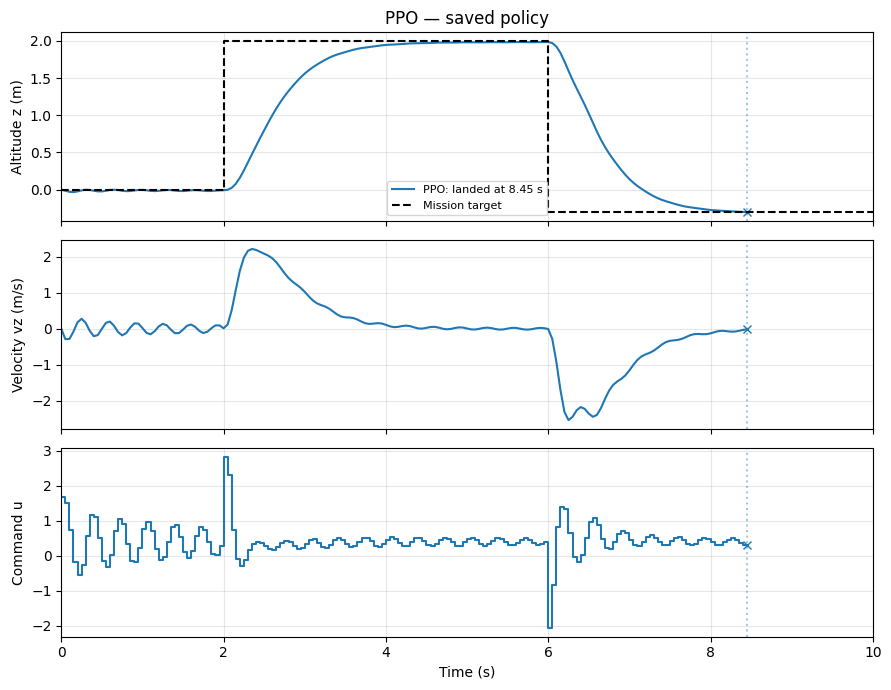

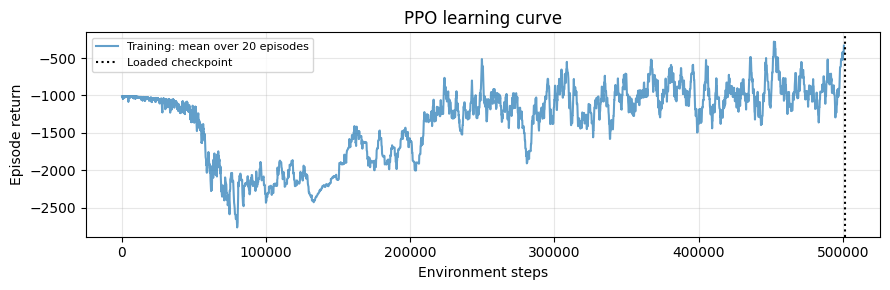

In [7]:
show_result("PPO", PPO_MODEL_PATH)


In [8]:
agent.save(MODEL_PATH := PROJECT_ROOT / "./rl_model/ppo_drone_rnn.zip")
print("Saved:", MODEL_PATH.with_suffix(".zip"))

EXPORT_MATLAB = True
if EXPORT_MATLAB:
    from export_policy import export_for_matlab
    export_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
    export_for_matlab(agent, export_env)
    from scipy.io import loadmat, savemat
    exported_policy = {k: v for k, v in loadmat("policy.mat").items() if not k.startswith("__")}
    mission_t = np.arange(export_env.max_steps + 1) * export_env.p.dt
    exported_policy["mission_t"] = mission_t.reshape(-1, 1)
    exported_policy["mission_z_ref"] = np.array([export_env.mission(float(t)) for t in mission_t]).reshape(-1, 1)
    savemat("policy.mat", exported_policy)
    export_env.close()

Saved: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_model/ppo_drone_rnn.zip
policy.mat and traj_model.mat written (169 steps): now run EINT_RL_eval in MATLAB.


## Changing mission

In [ ]:
def test_mission(t):
    """Hold at 0 m until 2 s, target 1 m until 4 s, then land."""
    if t < 2.0:
        return 0.0
    elif t < 4.0:
        return 9.0
    else:
        return Z_LAND

PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_interface/logs/rl_tuned_20261104_150629/ppo/ppo_drone_rnn.zip (501,760 training steps)
PPO: crashed at 5.40 s | return -3714.7 | MAE 2.385 m | peak altitude 8.213 m | final vz -2.651 m/s | RMS delta-u 0.556


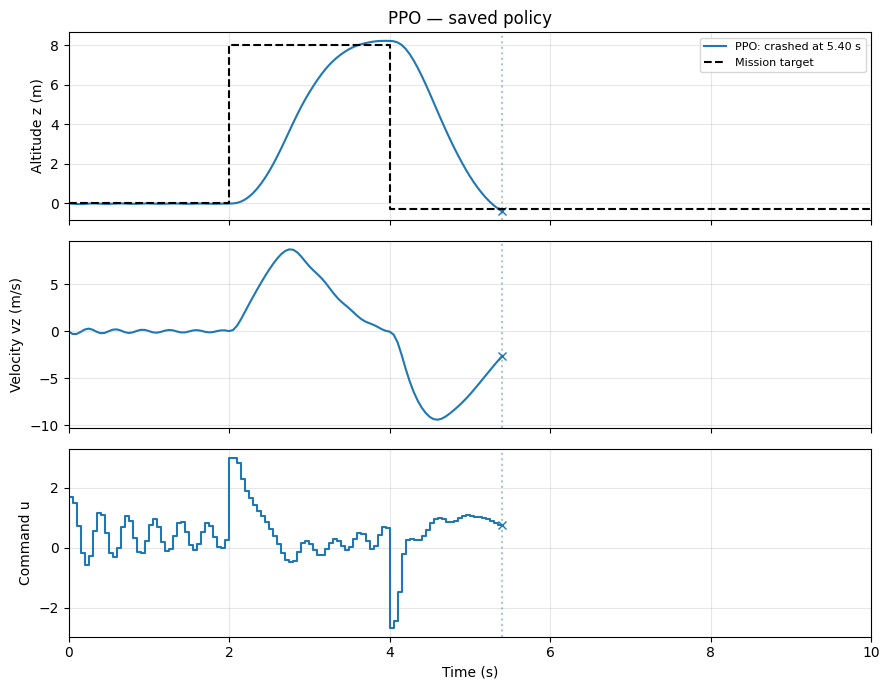

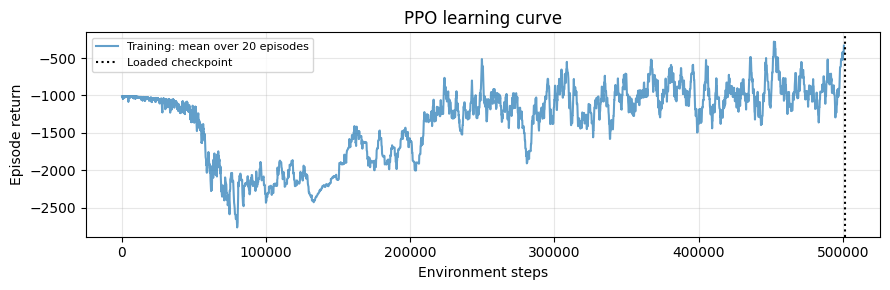

In [19]:
show_result("PPO", PPO_MODEL_PATH, mission_to_test=test_mission)

## DQN — optional training

Skipped when `SKIP_DQN=True` in Setup.

Use 61 commands evenly spaced across `[-3.0, 3.0]` (0.1 increments), covering
its full environment action range for the selected mission. Rerun this training
cell to learn with the wider command range; existing checkpoints retain their
original saved `commands.npy`. The Results cell reports peak altitude so you can
check whether the trained policy reaches its target.

Use learning rate `1e-4`, batch `128`, `train_freq=5`, and `gradient_steps=-1`:
with 10 environments, 50 collected transitions are followed by 50 updates.
`n_steps=3` passes rewards across three transitions; `tau=0.1` and
`target_update_interval=1000` smooth the target updates.
`exploration_fraction=1.0` decays epsilon throughout the training run.
These choices target sparse landing rewards and the observed training regressions.

Sources: [DQN parameters](https://stable-baselines3.readthedocs.io/en/master/modules/dqn.html#parameters),
[multi-environment update guidance](https://stable-baselines3.readthedocs.io/en/master/guide/examples.html#multiprocessing-with-off-policy-algorithms).


In [11]:
if SKIP_DQN:
    print("DQN skipped (SKIP_DQN=True).")
else:
    def make_dqn_env():
        env = DiscreteDroneActions(DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission))
        return env

    dqn_env = make_vec_env(make_dqn_env, n_envs=10, seed=SEED, monitor_dir=str(DQN_DIR))
    dqn_eval = make_vec_env(make_dqn_env, n_envs=1, seed=100)
    dqn_callback = EvalCallback(
        dqn_eval, best_model_save_path=str(DQN_DIR), log_path=str(DQN_DIR),
        eval_freq=500, n_eval_episodes=1, deterministic=True, verbose=0,
        callback_on_new_best=StopTrainingOnRewardThreshold(reward_threshold=0.0, verbose=1),
    )
    dqn_agent = DQN("MlpPolicy", dqn_env, seed=SEED, device="cpu", verbose=0, **DQN_PARAMS)
    start = time.perf_counter()
    dqn_agent.learn(total_timesteps=DQN_STEPS, callback=dqn_callback)
    dqn_agent.save(DQN_DIR / "dqn_drone_rnn")
    np.save(DQN_DIR / "commands.npy", DQN_COMMANDS)
    DQN_MODEL_PATH = DQN_DIR / "best_model.zip"
    dqn_env.close()
    dqn_eval.close()
    print(f"DQN: {dqn_agent.num_timesteps:,} steps in {time.perf_counter() - start:.1f} s; {DQN_MODEL_PATH}")


DQN skipped (SKIP_DQN=True).


## DQN — Results

Skipped when `SKIP_DQN=True` in Setup.

Loads only DQN and its saved `commands.npy`; PPO and SAC do not need to run.


In [12]:
if SKIP_DQN:
    print("DQN skipped (SKIP_DQN=True).")
else:
    show_result("DQN", DQN_MODEL_PATH)


DQN skipped (SKIP_DQN=True).


## SAC — optional training

Skipped when `SKIP_SAC=True` in Setup.

Use learning rate `3e-4`, batch `128`, and `gradient_steps=-1` to match updates
to collected transitions. Explore with `use_sde=True`, `sde_sample_freq=4`,
and `log_std_init=-2`: noise is resampled every 0.2 s instead of independently
at each 0.05 s action. Start entropy tuning at `auto_0.05` to reduce its initial
weight relative to the reward. The notebook wrapper advertises commands in
`[-0.8, 0.8]`; physical command units and library dynamics stay unchanged.

The best 30k-step checkpoint landed at 7.20 s. Later training regressed, so the
Results cell loads that best checkpoint, not the final 50k-step policy.
These values were tested together; their individual effects are unproven.
Sources: [SAC parameters](https://stable-baselines3.readthedocs.io/en/master/modules/sac.html#parameters),
[Smooth Exploration for Robotic Reinforcement Learning](https://arxiv.org/abs/2005.05719),
[RL Zoo SAC configurations](https://github.com/DLR-RM/rl-baselines3-zoo/blob/master/hyperparams/sac.yml).
The sources support the approach; they do not prescribe these exact values for this drone.


In [13]:
if SKIP_SAC:
    print("SAC skipped (SKIP_SAC=True).")
else:
    def make_sac_env():
        env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
        if SAC_ACTION_LIMIT is not None:
            env = LimitedCommands(env, SAC_ACTION_LIMIT)
        return env

    sac_env = make_vec_env(make_sac_env, n_envs=10, seed=SEED, monitor_dir=str(SAC_DIR))
    sac_eval = make_vec_env(make_sac_env, n_envs=1, seed=100)
    sac_callback = EvalCallback(
        sac_eval, best_model_save_path=str(SAC_DIR), log_path=str(SAC_DIR),
        eval_freq=500, n_eval_episodes=1, deterministic=True, verbose=0,
        callback_on_new_best=StopTrainingOnRewardThreshold(reward_threshold=0.0, verbose=1),
    )
    sac_agent = SAC("MlpPolicy", sac_env, seed=SEED, device="cpu", verbose=0, **SAC_PARAMS)
    start = time.perf_counter()
    sac_agent.learn(total_timesteps=SAC_STEPS, callback=sac_callback)
    sac_agent.save(SAC_DIR / "sac_drone_rnn")
    SAC_MODEL_PATH = SAC_DIR / "best_model.zip"
    sac_env.close()
    sac_eval.close()
    print(f"SAC: {sac_agent.num_timesteps:,} steps in {time.perf_counter() - start:.1f} s; {SAC_MODEL_PATH}")


SAC skipped (SKIP_SAC=True).


## SAC — Results

Skipped when `SKIP_SAC=True` in Setup.

Loads only SAC; PPO and DQN do not need to run.


In [14]:
if SKIP_SAC:
    print("SAC skipped (SKIP_SAC=True).")
else:
    show_result("SAC", SAC_MODEL_PATH)


SAC skipped (SKIP_SAC=True).


## Export a PPO trajectory

Exports `trajectory_az.csv` into this run's PPO directory using the same selected
mission. MATLAB policy export above also includes that mission's reference samples.


In [15]:

# 1. Déroulement d'un épisode avec la politique entraînée
eval_env = DroneEnv(rnn_model=acceleration_rnn)
obs, info = eval_env.reset(seed=0)

az_list = [float(eval_env.unwrapped.state[2])]

terminated = False
truncated = False

while not (terminated or truncated):
    action, _ = agent.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = eval_env.step(action)
    az_list.append(float(eval_env.unwrapped.state[2]))

eval_env.close()

# 2. Export sur une seule ligne (chaque case = une valeur de az)
output_path = LOG_DIR / "trajectory_az.csv"
np.savetxt(output_path, [az_list], delimiter=",", fmt="%.6f")

print(f"Trajectoire az exportée ({len(az_list)} valeurs sur 1 ligne) : {output_path}")

FileNotFoundError: [Errno 2] No such file or directory: '/home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_interface/export_logs/trajectory_az.csv'